# Лабораторная № 4. Байесовская сеть

**Темников Дмитрий Павлович, М8О-306БВ-24, № 26 в списке**

Одна строка — образец красного или белого португальского вина. Используем четыре переменные. [Wine Quality, Cortez et al. (2009), UCI](https://doi.org/10.24432/C56S3T)

## 1. Данные и вопросы

- `Red` — красное вино. Значение `False` соответствует белому.
- `Strong` — содержание алкоголя от 11%. `Acidic` — летучая кислотность от 0.30.
- `Good` — дегустационная оценка от 7 баллов.

Для алкоголя и кислотности берём простые пороги вблизи медиан (10.3% и 0.29). Два состояния на признак оставляют достаточно примеров в подгруппах. Высокие оценки объединяем в одну категорию, поскольку крайние баллы редки.

1. Как изменится вероятность высокой оценки, если известно, что вино крепкое?
2. Как изменится вероятность повышенной кислотности, если вино красное?
3. Какова вероятность высокой оценки у красного крепкого вина с кислотностью ниже порога?

In [15]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

csv = Path('regression/data/winequality-combined.csv')
path = next(path for path in (Path('..') / csv, csv, Path('ml_course_mai') / csv) if path.is_file())
raw = pd.read_csv(path, sep=';')
columns = ['wine_type', 'alcohol', 'volatile acidity', 'quality']
print(f'Образцов: {len(raw)}. Пропусков в выбранных столбцах: {raw[columns].isna().sum().sum()}')
print(f'Оценки 3 и 9: {(raw["quality"] == 3).sum()} и {(raw["quality"] == 9).sum()} образцов.')

data = pd.DataFrame({
    'Red': raw['wine_type'] == 0,
    'Strong': raw['alcohol'] >= 11,
    'Acidic': raw['volatile acidity'] >= 0.30,
    'Good': raw['quality'] >= 7,
})
display(data.apply(pd.Series.value_counts).T)

Образцов: 6497. Пропусков в выбранных столбцах: 0
Оценки 3 и 9: 30 и 5 образцов.


,False,True
Red,4898,1599
Strong,4311,2186
Acidic,3290,3207
Good,5220,1277


## 2. Граф

- **Red → Strong, Acidic.** Технология производства красного и белого вина различается. Тип задаём раньше показателей состава.
- **Strong, Acidic → Good.** Алкоголь и летучая кислотность связаны со вкусом. Состав известен до выставления оценки.
- **Red → Good.** Тип может быть связан с оценкой через свойства, которых нет среди выбранных переменных.

Все стрелки направлены от типа к составу и оценке либо от состава к оценке. Циклов нет.

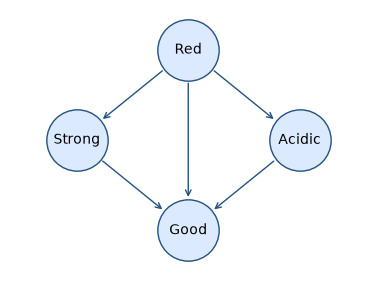

In [16]:
parents = {
    'Red': [],
    'Strong': ['Red'],
    'Acidic': ['Red'],
    'Good': ['Red', 'Strong', 'Acidic'],
}

positions = {'Red': (0, 2), 'Strong': (-1, 1), 'Acidic': (1, 1), 'Good': (0, 0)}
fig, ax = plt.subplots(figsize=(4.6, 3.4))
for node, given in parents.items():
    x, y = positions[node]
    ax.scatter(x, y, s=1950, color='#dbeafe', edgecolors='#245281', zorder=3)
    ax.text(x, y, node, ha='center', va='center', zorder=4)
    for parent in given:
        ax.annotate('', xy=(x, y), xytext=positions[parent],
                    arrowprops=dict(arrowstyle='->', color='#245281', shrinkA=24, shrinkB=24))
ax.set(xlim=(-1.6, 1.6), ylim=(-0.45, 2.45))
ax.axis('off')
plt.show()

## 3. Условные вероятности

Для каждого сочетания родителей `p` — доля строк, в которых узел равен `True`, а `N` — число этих строк. Совместную вероятность состояния сети получаем произведением вероятностей всех узлов с учётом их родителей.

In [17]:
def fit_network(parents):
    joint = pd.DataFrame(product([False, True], repeat=len(parents)), columns=list(parents))
    joint['P'] = 1.0
    tables = {}
    for node, given in parents.items():
        if given:
            table = data.groupby(given)[node].agg(N='size', p='mean')
            p = joint.join(table['p'], on=given)['p']
        else:
            p = data[node].mean()
            table = pd.DataFrame({'N': [len(data)], 'p': [p]})
        joint['P'] *= np.where(joint[node], p, 1 - p)
        tables[node] = table
    return joint, tables


joint, tables = fit_network(parents)
display(tables['Acidic'].round(3), tables['Good'].round(3))

,N,p
Red,,
False,4898,0.354
True,1599,0.921


N      p
Red   Strong Acidic             
False False  False   2142  0.150
             True    1037  0.022
      True   False   1021  0.369
             True     698  0.486
True  False  False     70  0.200
             True    1062  0.046
      True   False     57  0.544
             True     410  0.300

Повышенная кислотность встречается у 92% красных и 35% белых вин. В таблице оценки в каждой паре «тип и кислотность» доля высоких оценок выше у крепкого вина. У крепкого белого вина эта доля неожиданно выше при повышенной кислотности (49% против 37%). Возможно, группы различаются и по другим свойствам, например по остаточному сахару. В каждой группе таблицы оценки есть хотя бы 57 образцов.

## 4. Вероятностные запросы

Суммируем вероятности состояний, которые удовлетворяют условию и событию, и делим на вероятность условия. Для сверки считаем те же доли напрямую по данным.

In [18]:
def probability(joint, event, **evidence):
    for node, value in evidence.items():
        joint = joint[joint[node] == value]
    return joint.loc[joint[event], 'P'].sum() / joint['P'].sum()


observed = data.assign(P=1 / len(data))
queries = [
    ('Good', {'Strong': True}),
    ('Acidic', {'Red': True}),
    ('Good', {'Red': True, 'Strong': True, 'Acidic': False}),
]
results = []
for event, evidence in queries:
    results.append({
        'Сеть до, %': 100 * probability(joint, event),
        'Сеть после, %': 100 * probability(joint, event, **evidence),
        'Данные до, %': 100 * probability(observed, event),
        'Данные после, %': 100 * probability(observed, event, **evidence),
    })
display(pd.DataFrame(results, index=[1, 2, 3]).round(1))

,"Сеть до, %","Сеть после, %","Данные до, %","Данные после, %"
1,19.3,39.1,19.7,39.8
2,49.4,92.1,49.4,92.1
3,19.3,54.4,19.7,54.4


1. Сведения о крепости повышают вероятность высокой оценки с **19,3% до 39,1%**.
2. У красного вина вероятность повышенной кислотности растёт с **49,4% до 92,1%**.
3. Для крепкого красного вина с кислотностью ниже порога вероятность высокой оценки — **54,4%**. В этой группе 57 образцов.

Небольшое расхождение с долями из CSV связано с тем, что сеть считает крепость и кислотность независимыми при известном типе вина.

## 5. Что меняется с новыми сведениями

In [ ]:
steps = {
    'Без сведений': {},
    'Красное': {'Red': True},
    '+ крепкое': {'Red': True, 'Strong': True},
    '+ кислотность ниже 0.30': {'Red': True, 'Strong': True, 'Acidic': False},
}
good = pd.Series({label: 100 * probability(joint, 'Good', **evidence)
                  for label, evidence in steps.items()})
display(pd.DataFrame({'Оценка ≥ 7, %': good, 'Оценка < 7, %': 100 - good}).round(1))

Красный тип снижает оценку вероятности с 19,3% до 13,5%. Сведения о крепости повышают её до 31,9%, а о кислотности ниже порога — до 54,4%. Все три признака входят в таблицу узла `Good`. Пока часть признаков неизвестна, сеть усредняет по их возможным значениям.

## 6. Удаление ребра

Удаляем **Strong → Good**, заново оцениваем таблицы по тем же данным и повторяем первый запрос.

In [20]:
reduced_parents = {**parents, 'Good': ['Red', 'Acidic']}
reduced, _ = fit_network(reduced_parents)
comparison = {}
for label, network in [('Исходная сеть', joint), ('Без ребра Strong → Good', reduced)]:
    comparison[label] = [100 * probability(network, 'Good'),
                         100 * probability(network, 'Good', Strong=True)]
display(pd.DataFrame.from_dict(
    comparison, orient='index', columns=['До, %', 'Если крепкое, %']
).round(1))

,"До, %","Если крепкое, %"
Исходная сеть,19.3,39.1
Без ребра Strong → Good,19.7,19.9


После удаления ребра вероятность высокой оценки крепкого вина падает с 39,1% до 19,9%. Теперь крепость даёт информацию об оценке только косвенно, через общий узел `Red`. Когда тип уже известен, сведения о крепости больше не меняют прогноз оценки в этой сети.

**Причинность.** Сеть описывает наблюдаемые зависимости. Время измерения состава и выставления оценки подсказывает направление стрелок. По одним частотам трудно восстановить это направление, поскольку разные графы могут описывать одно распределение. Чтобы судить о влиянии самого алкоголя, понадобился бы эксперимент с контролем других свойств вина.

## Вывод

Крепость и тип вина дают заметную информацию об оценке и кислотности. В выбранном примере сочетание сведений о составе повышает вероятность высокой оценки красного вина. Удаление связи крепости с оценкой резко ослабляет её вклад в прогноз. Ограничения модели — грубые пороги, допущение независимости крепости и кислотности внутри типа, а также данные только по винам Vinho Verde.